In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
transactions = [
    ['Book A','Book B','Book C'],
    ['Book A','Book C'],
    ['Book A','Book B'],
    ['Book B','Book C'],
    ['Book A','Book B','Book C'],
    ['Book A','Book D'],
    ['Book B','Book C','Book D'],
    ['Book A','Book B','Book D'],
    ['Book A','Book C','Book D'],
    ['Book B','Book D']
]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
transaction_table = pd.DataFrame({
    "Transaction ID":[f"T{i+1}" for i in range(len(transactions))],
    "Books Purchased":[", ".join(t) for t in transactions]
})

print(transaction_table)

  Transaction ID         Books Purchased
0             T1  Book A, Book B, Book C
1             T2          Book A, Book C
2             T3          Book A, Book B
3             T4          Book B, Book C
4             T5  Book A, Book B, Book C
5             T6          Book A, Book D
6             T7  Book B, Book C, Book D
7             T8  Book A, Book B, Book D
8             T9  Book A, Book C, Book D
9            T10          Book B, Book D


In [ ]:
te = TransactionEncoder()

te_array = te.fit(transactions).transform(transactions)

df = pd.DataFrame(te_array,columns=te.columns_)

print(df)

   Book A  Book B  Book C  Book D
0    True    True    True   False
1    True   False    True   False
2    True    True   False   False
3   False    True    True   False
4    True    True    True   False
5    True   False   False    True
6   False    True    True    True
7    True    True   False    True
8    True   False    True    True
9   False    True   False    True


In [ ]:
support=df.sum()

support_df=pd.DataFrame({
    "Book":support.index,
    "Support Count":support.values,
    "Support %":support.values/len(df)*100
})

print(support_df)

     Book  Support Count  Support %
0  Book A              7       70.0
1  Book B              7       70.0
2  Book C              6       60.0
3  Book D              5       50.0


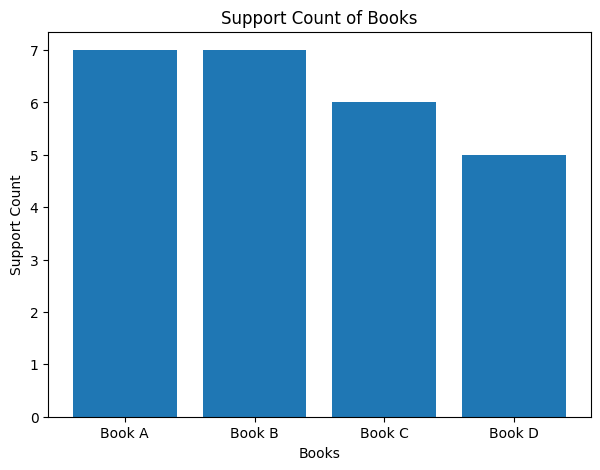

In [ ]:
plt.figure(figsize=(7,5))

plt.bar(support_df["Book"],
        support_df["Support Count"])

plt.title("Support Count of Books")
plt.xlabel("Books")
plt.ylabel("Support Count")

plt.show()

In [ ]:
frequent_itemsets = apriori(df,
                            min_support=0.4,
                            use_colnames=True)

print(frequent_itemsets)

   support          itemsets
0      0.7          (Book A)
1      0.7          (Book B)
2      0.6          (Book C)
3      0.5          (Book D)
4      0.4  (Book B, Book A)
5      0.4  (Book A, Book C)
6      0.4  (Book B, Book C)


In [ ]:
frequent_itemsets["Support %"]=frequent_itemsets["support"]*100

print(frequent_itemsets)

   support          itemsets  Support %
0      0.7          (Book A)       70.0
1      0.7          (Book B)       70.0
2      0.6          (Book C)       60.0
3      0.5          (Book D)       50.0
4      0.4  (Book B, Book A)       40.0
5      0.4  (Book A, Book C)       40.0
6      0.4  (Book B, Book C)       40.0


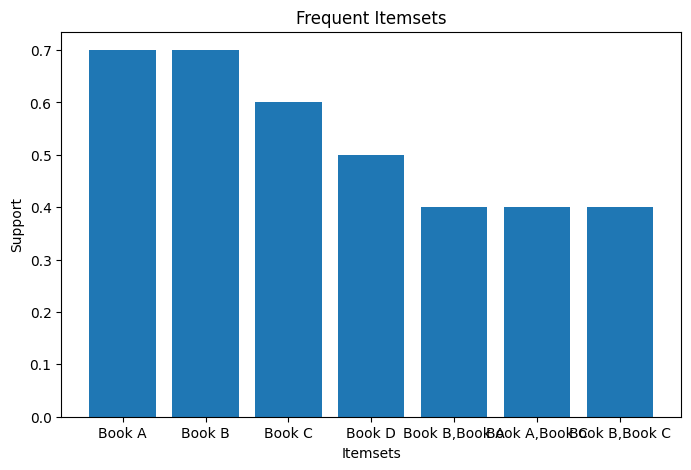

In [ ]:
labels=[]

for item in frequent_itemsets['itemsets']:
    labels.append(",".join(list(item)))

plt.figure(figsize=(8,5))

plt.bar(labels,
        frequent_itemsets['support'])

plt.xlabel("Itemsets")
plt.ylabel("Support")

plt.title("Frequent Itemsets")

plt.show()

In [ ]:
rules = association_rules(frequent_itemsets,
                          metric="confidence",
                          min_threshold=0.6)

rules=rules[[
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]]

print(rules)

  antecedents consequents  support  confidence      lift
0    (Book C)    (Book A)      0.4    0.666667  0.952381
1    (Book C)    (Book B)      0.4    0.666667  0.952381


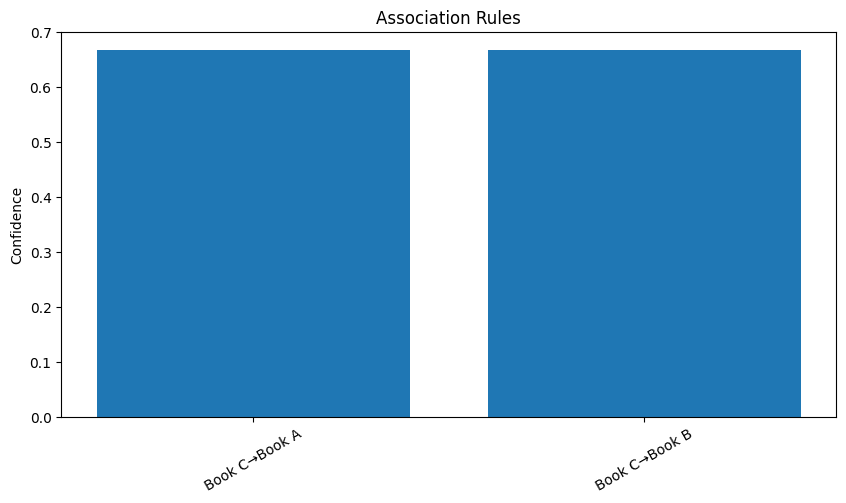

In [ ]:
labels=[]

for i in range(len(rules)):
    labels.append(
        ",".join(list(rules.iloc[i]["antecedents"]))+
        "→"+
        ",".join(list(rules.iloc[i]["consequents"]))
    )

plt.figure(figsize=(10,5))

plt.bar(labels,
        rules["confidence"])

plt.xticks(rotation=30)

plt.ylabel("Confidence")

plt.title("Association Rules")

plt.show()

In [ ]:
print("""
Interpretation

1. Books A and B have highest support.

2. Books C and A are frequently purchased together.

3. Confidence greater than 60% means
customers buying Book C are likely to buy Book A.

4. These rules can be used for
recommendation systems,
cross-selling,
marketing campaigns,
and product placement.
""")


Interpretation

1. Books A and B have highest support.

2. Books C and A are frequently purchased together.

3. Confidence greater than 60% means
customers buying Book C are likely to buy Book A.

4. These rules can be used for
recommendation systems,
cross-selling,
marketing campaigns,
and product placement.

